# Visualiser l’entrée réelle de YOLO

Ce notebook utilise directement `ultralytics.data.dataset.YOLODataset` : resize/letterbox, Mosaic, transformations géométriques, HSV, flips, etc. suivent donc la même chaîne que `model.train()`. La normalisation finale `/ 255` est également appliquée avant l’affichage.

1. Régler les chemins et les options dans la cellule suivante.
2. Exécuter les cellules dans l’ordre.
3. Relancer uniquement la dernière cellule pour tirer de nouvelles images et de nouvelles augmentations aléatoires.

> Si la configuration contient `mosaic: 0`, `degrees: 0`, etc., ces augmentations sont réellement désactivées. Utiliser `OVERRIDES` pour tester une variante sans modifier le YAML d’entraînement.

In [9]:
from pathlib import Path

# Peut être un dossier contenant directement des images, une racine contenant
# images/<split>, ou même .../split_max_coverage_train_val_test/test.
IMAGE_FOLDER = Path("datasets/LPL_dataset_final/dataset")
SPLIT = "test"  # train, val ou test

TRAIN_CONFIG = Path("detection/train_config_yolo.yaml")
DATA_YAML = Path("datasets/LPL_dataset_final/dataset/data.yaml")  # None autorisé

NUM_IMAGES = 4
IMGSZ_OVERRIDE = None  # Exemples : 320, 640, 1280. None = valeur du YAML.
APPLY_AUGMENTATIONS = True
SIMULATE_LAST_EPOCHS = False  # True simule la période close_mosaic.
MAX_DISPLAY_EDGE = 1400  # Réduit seulement l'affichage des originaux, pas le traitement YOLO.

# Ces valeurs remplacent temporairement celles du YAML, uniquement dans ce notebook.
# Exemple : {"mosaic": 1.0, "degrees": 30, "hsv_s": 0.5, "fliplr": 0.5}
OVERRIDES = {}

## Construction de la même pipeline qu’à l’entraînement

Après avoir changé un chemin, `imgsz`, `OVERRIDES` ou une autre option ci-dessus, relancer cette cellule puis la dernière.

In [10]:
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics.cfg import get_cfg
from ultralytics.data.dataset import YOLODataset
from ultralytics.data.utils import IMG_FORMATS, img2label_paths

def find_repo_root(start=Path.cwd()):
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "detection").is_dir() and (candidate / "main.py").is_file():
            return candidate
    raise FileNotFoundError("Impossible de trouver la racine AquaIA. Lancez le notebook depuis le dépôt.")

REPO_ROOT = find_repo_root()

def absolute(path):
    if path is None:
        return None
    path = Path(path)
    return path if path.is_absolute() else REPO_ROOT / path

def has_images(folder):
    if not folder.is_dir():
        return False
    return any(p.is_file() and p.suffix.lower().lstrip(".") in IMG_FORMATS for p in folder.iterdir())

def resolve_image_folder(path, split):
    path = absolute(path)
    candidates = [
        path,
        path / "images" / split,
        path / split,
        path.parent / "images" / path.name,  # accepte .../racine/test
    ]
    for candidate in candidates:
        if has_images(candidate):
            return candidate.resolve()
    tried = "\n".join(f"- {p}" for p in candidates)
    raise FileNotFoundError(f"Aucune image trouvée. Dossiers essayés :\n{tried}")

def read_names(data_yaml, label_paths):
    names = {}
    data_yaml = absolute(data_yaml)
    if data_yaml is not None and data_yaml.is_file():
        raw_names = (yaml.safe_load(data_yaml.read_text()) or {}).get("names", {})
        if isinstance(raw_names, list):
            names = {i: name for i, name in enumerate(raw_names)}
        elif isinstance(raw_names, dict):
            names = {int(i): name for i, name in raw_names.items()}

    max_class = -1
    for label_path in label_paths:
        path = Path(label_path)
        if not path.is_file():
            continue
        for line in path.read_text().splitlines():
            fields = line.split()
            if fields:
                max_class = max(max_class, int(float(fields[0])))
    for class_id in range(max(max_class + 1, len(names), 1)):
        names.setdefault(class_id, f"classe_{class_id}")
    return names

config_path = absolute(TRAIN_CONFIG)
config = yaml.safe_load(config_path.read_text())
training = dict(config.get("training", config))
training.update(OVERRIDES)
imgsz = int(IMGSZ_OVERRIDE if IMGSZ_OVERRIDE is not None else training.get("imgsz", 640))
image_folder = resolve_image_folder(IMAGE_FOLDER, SPLIT)
image_files = sorted(
    str(p) for p in image_folder.iterdir()
    if p.is_file() and p.suffix.lower().lstrip(".") in IMG_FORMATS
)
label_files = img2label_paths(image_files)
names = read_names(DATA_YAML, label_files)

hyp = get_cfg()
unknown = []
for key, value in training.items():
    if hasattr(hyp, key):
        setattr(hyp, key, value)
    else:
        unknown.append(key)
if unknown:
    warnings.warn("Paramètres ignorés par la pipeline d'image Ultralytics : " + ", ".join(unknown))

configured_batch = training.get("batch", 16)
dataset_batch = configured_batch if isinstance(configured_batch, int) and configured_batch > 0 else 16
preview_dataset = YOLODataset(
    img_path=str(image_folder),
    imgsz=imgsz,
    augment=APPLY_AUGMENTATIONS,
    hyp=hyp,
    rect=False,
    batch_size=dataset_batch,
    stride=32,
    cache=False,
    single_cls=bool(training.get("single_cls", False)),
    data={"names": names, "channels": 3},
    task="detect",
    prefix="Prévisualisation : ",
)
if SIMULATE_LAST_EPOCHS and APPLY_AUGMENTATIONS:
    preview_dataset.close_mosaic(hyp)

augmentation_keys = [
    "hsv_h", "hsv_s", "hsv_v", "degrees", "translate", "scale",
    "shear", "perspective", "flipud", "fliplr", "mosaic", "mixup",
    "cutmix", "copy_paste", "bgr", "close_mosaic",
]
active_settings = {"imgsz": imgsz, **{k: getattr(hyp, k, None) for k in augmentation_keys}}
print(f"Dossier résolu : {image_folder}")
print(f"{len(preview_dataset)} images | imgsz={imgsz} | augmentations={APPLY_AUGMENTATIONS}")
display(pd.Series(active_settings, name="valeur effective").to_frame())

Prévisualisation : Fast image access ✅ (ping: 0.0±0.0 ms, read: 2002.1±96.1 MB/s, size: 117612.1 KB)
Prévisualisation : Scanning /home/benjamin.yang/Documents/AKKODIS/AquaIA/datasets/LPL_dataset_final/dataset/labels/test... 16 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16/16 750.5it/s 0.0s
Prévisualisation : New cache created: /home/benjamin.yang/Documents/AKKODIS/AquaIA/datasets/LPL_dataset_final/dataset/labels/test.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
Dossier résolu : /home/benjamin.yang/Documents/AKKODIS/AquaIA/datasets/LPL_dataset_final/dataset/images/test
16 images | imgsz=640 | augmentations=True


,valeur effective
imgsz,640.0
hsv_h,0.5
hsv_s,0.5
hsv_v,0.5
degrees,180.0
translate,0.1
scale,0.3
shear,0.0
perspective,0.0
flipud,0.5


## Fonctions d’affichage

Les dimensions de petites boîtes sont indiquées en pixels. À gauche elles sont mesurées dans l’image originale ; à droite dans l’entrée réellement redimensionnée donnée au modèle. Mosaic peut changer le nombre d’objets et mélanger plusieurs images.

In [11]:
def as_numpy(value):
    if hasattr(value, "detach"):
        value = value.detach().cpu().numpy()
    return np.asarray(value)

def min_box_size(bboxes, width, height):
    bboxes = as_numpy(bboxes).reshape(-1, 4)
    if len(bboxes) == 0:
        return None
    sizes = np.column_stack((bboxes[:, 2] * width, bboxes[:, 3] * height))
    smallest = sizes[np.argmin(sizes[:, 0] * sizes[:, 1])]
    return float(smallest[0]), float(smallest[1])

def size_text(size):
    return "—" if size is None else f"{size[0]:.1f} × {size[1]:.1f} px"

def draw_boxes(ax, image, bboxes, classes, title, metric_shape=None):
    ax.imshow(image)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    display_h, display_w = image.shape[:2]
    metric_h, metric_w = metric_shape or (display_h, display_w)
    bboxes = as_numpy(bboxes).reshape(-1, 4)
    classes = as_numpy(classes).reshape(-1)
    for bbox, class_id in zip(bboxes, classes):
        xc, yc, bw, bh = bbox
        x = (xc - bw / 2) * display_w
        y = (yc - bh / 2) * display_h
        rect = Rectangle((x, y), bw * display_w, bh * display_h, fill=False, edgecolor="lime", linewidth=1.5)
        ax.add_patch(rect)
        class_id = int(class_id)
        label = f"{names.get(class_id, class_id)} | {bw * metric_w:.0f}×{bh * metric_h:.0f}px"
        ax.text(x, max(0, y - 3), label, color="black", fontsize=7,
                bbox={"facecolor": "lime", "alpha": 0.75, "pad": 1})

def load_original(path):
    with Image.open(path) as pil_image:
        pil_image = pil_image.convert("RGB")
        original_size = pil_image.size
        pil_image.thumbnail((MAX_DISPLAY_EDGE, MAX_DISPLAY_EDGE), Image.Resampling.LANCZOS)
        return np.asarray(pil_image), original_size

def show_random_images(count=NUM_IMAGES):
    count = min(int(count), len(preview_dataset))
    indices = random.sample(range(len(preview_dataset)), count)
    fig, axes = plt.subplots(count, 2, figsize=(16, 6 * count), squeeze=False)
    summary = []

    for row, index in enumerate(indices):
        original_label = preview_dataset.labels[index]
        original_image, (original_w, original_h) = load_original(preview_dataset.im_files[index])
        original_boxes = original_label["bboxes"]
        original_classes = original_label["cls"]

        # __getitem__ exécute ici les augmentations aléatoires réelles d'Ultralytics.
        processed_sample = preview_dataset[index]
        processed_image = processed_sample["img"].float().div(255).permute(1, 2, 0).cpu().numpy()
        processed_boxes = processed_sample["bboxes"]
        processed_classes = processed_sample["cls"]
        processed_h, processed_w = processed_image.shape[:2]

        filename = Path(preview_dataset.im_files[index]).name
        draw_boxes(
            axes[row, 0], original_image, original_boxes, original_classes,
            f"Original — {filename}\n{original_w} × {original_h}px",
            metric_shape=(original_h, original_w),
        )
        draw_boxes(
            axes[row, 1], processed_image, processed_boxes, processed_classes,
            f"Entrée YOLO après pipeline — {processed_w} × {processed_h}px",
        )

        summary.append({
            "image source": filename,
            "taille originale": f"{original_w} × {original_h}",
            "taille YOLO": f"{processed_w} × {processed_h}",
            "objets avant": len(as_numpy(original_boxes).reshape(-1, 4)),
            "objets après": len(as_numpy(processed_boxes).reshape(-1, 4)),
            "plus petite bbox avant": size_text(min_box_size(original_boxes, original_w, original_h)),
            "plus petite bbox après": size_text(min_box_size(processed_boxes, processed_w, processed_h)),
        })

    fig.suptitle(
        f"Configuration : {config_path.name} | imgsz={imgsz} | augmentations={APPLY_AUGMENTATIONS}",
        fontsize=14, y=1.0,
    )
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(summary)

## À relancer pour obtenir de nouveaux exemples

Chaque exécution sélectionne de nouvelles images et rejoue les transformations aléatoires.

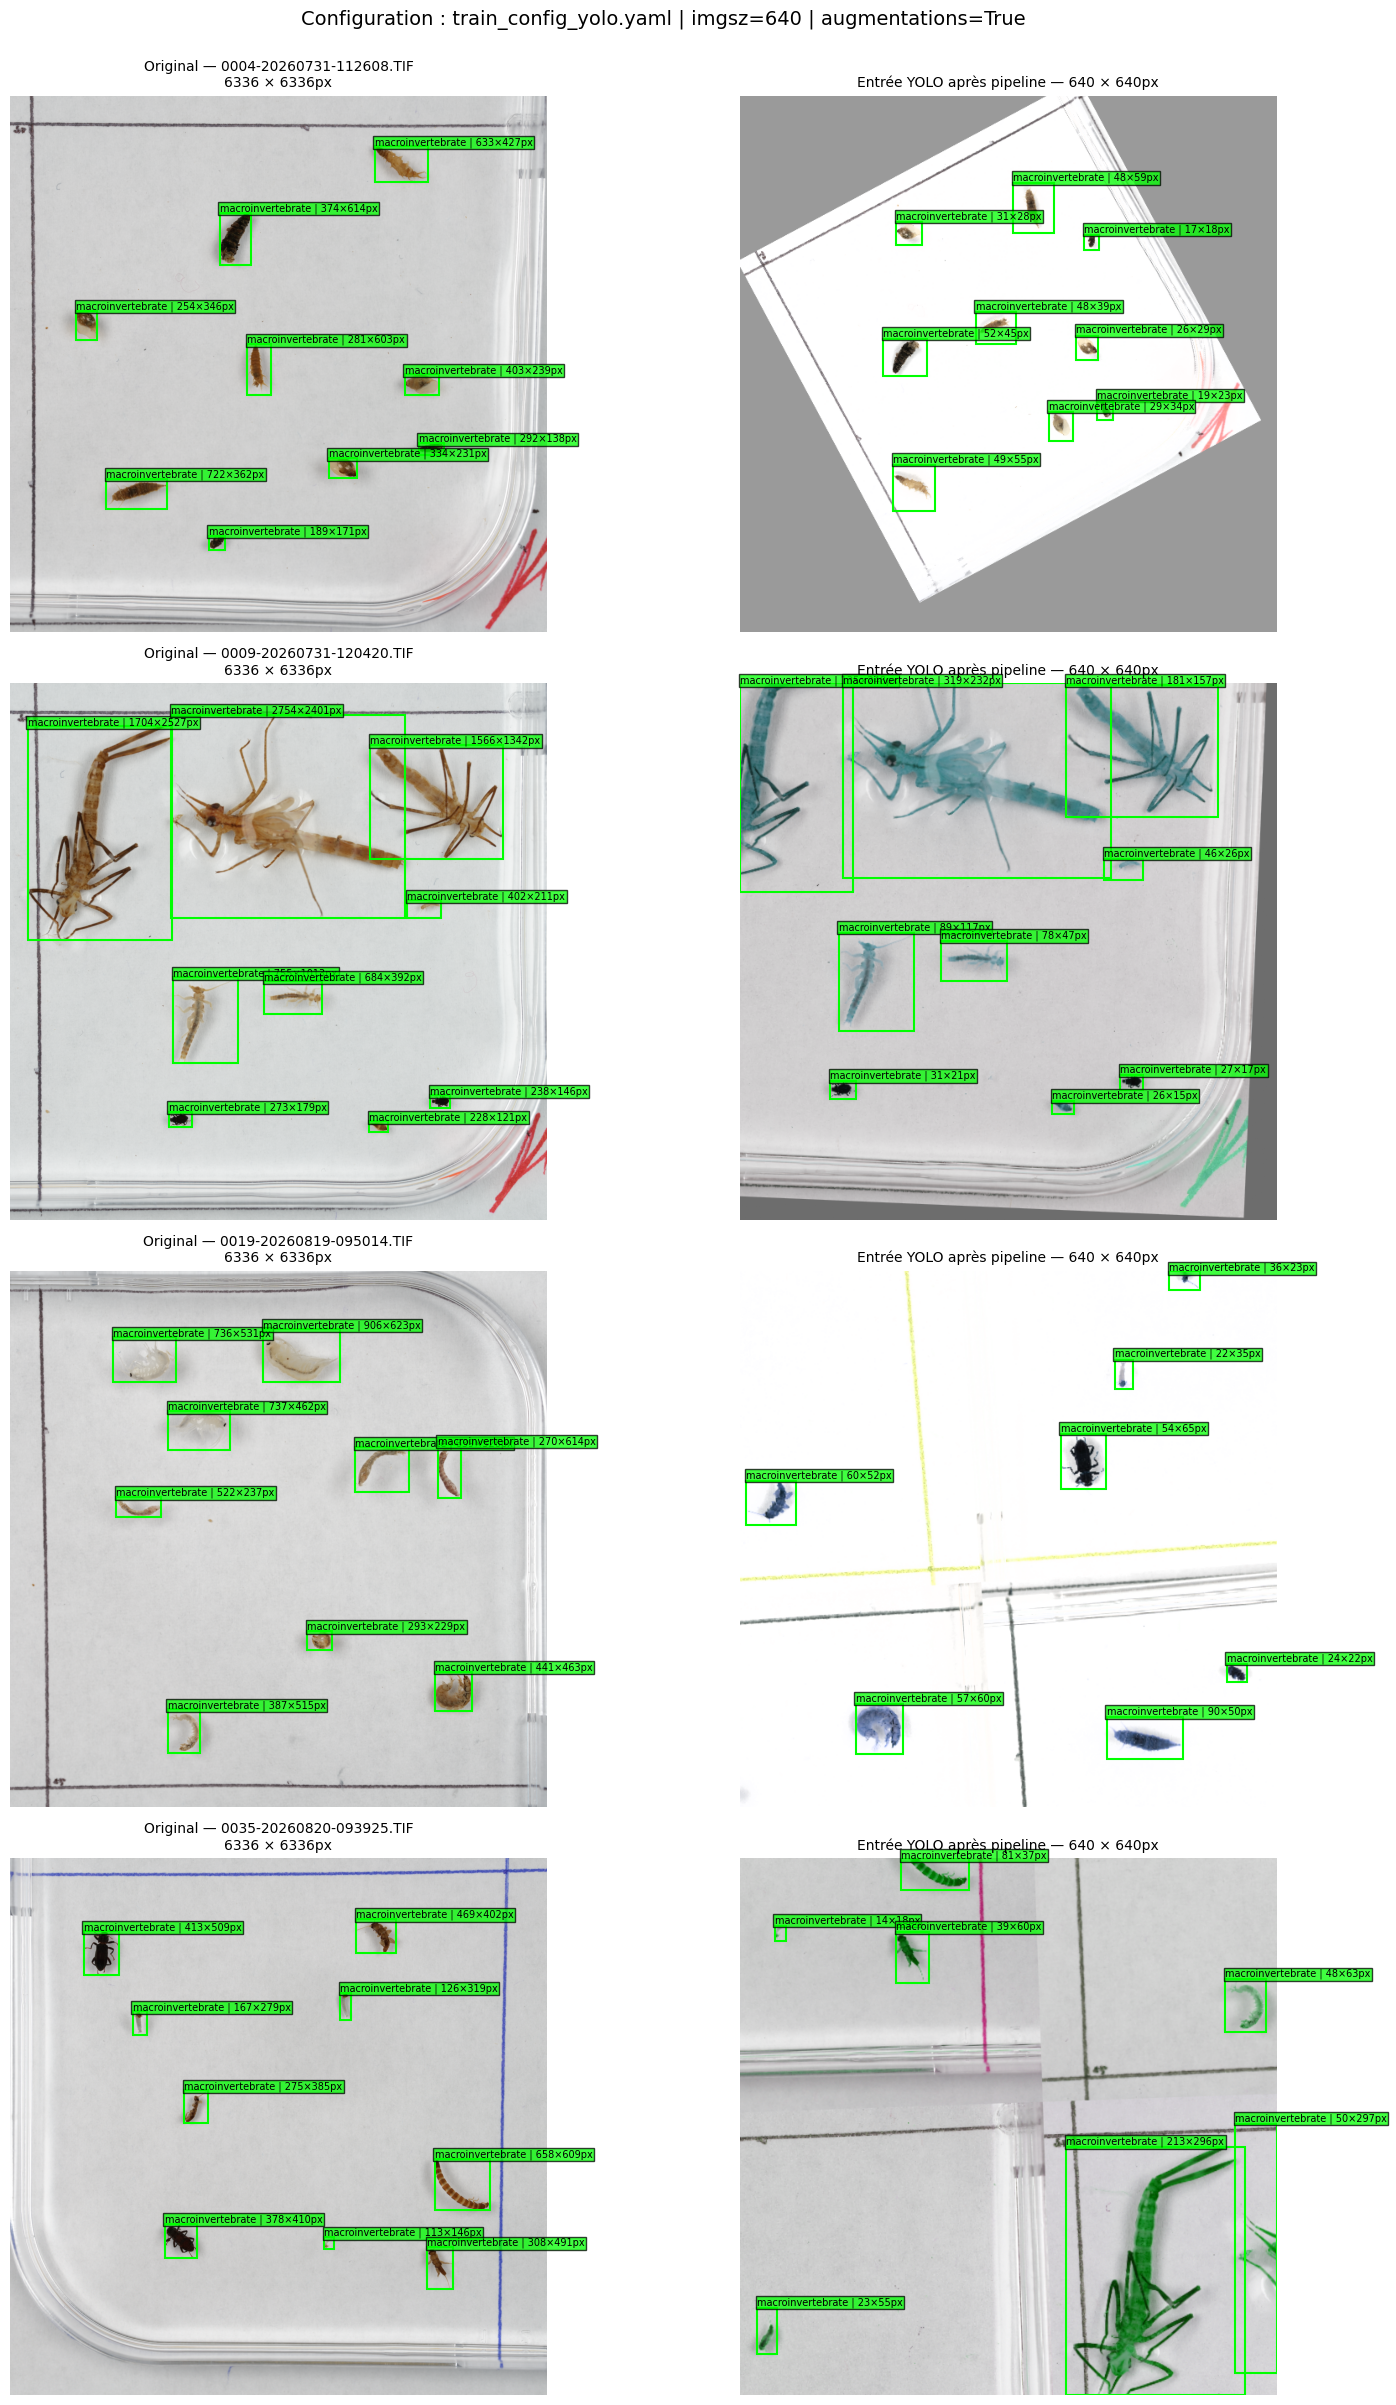

,image source,taille originale,taille YOLO,objets avant,objets après,plus petite bbox avant,plus petite bbox après
0,0004-20260731-112608.TIF,6336 × 6336,640 × 640,9,9,188.8 × 170.9 px,17.5 × 18.0 px
1,0009-20260731-120420.TIF,6336 × 6336,640 × 640,9,9,228.1 × 120.7 px,26.1 × 14.6 px
2,0019-20260819-095014.TIF,6336 × 6336,640 × 640,9,7,292.7 × 229.1 px,24.2 × 22.2 px
3,0035-20260820-093925.TIF,6336 × 6336,640 × 640,9,7,113.3 × 146.4 px,14.1 × 17.9 px


In [13]:
show_random_images(NUM_IMAGES)